# Customer Churn Analysis
## Data Cleaning and Exploratory Data Analysis (EDA)

**Project:** AWS Customer Churn Prediction

**Objective:** To inspect the Telco Customer Churn dataset, clean the data, identify important patterns, and visualize customer churn.

**Tools:** Python, Pandas, Matplotlib, Seaborn, Google Colab


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Libraries imported successfully.")

Libraries imported successfully.


In [19]:
DATA_PATH = "/content/drive/MyDrive/AWS-Customer-Churn/Telco-Customer-Churn.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Dataset loaded successfully.
Number of rows: 7043
Number of columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [20]:
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df) * 100).round(2)
})

display(missing_summary[missing_summary["Missing Values"] > 0])

if missing_summary["Missing Values"].sum() == 0:
    print("No missing values found using isnull().")

,Missing Values,Missing Percentage


No missing values found using isnull().


In [22]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

df = df.drop_duplicates().copy()

print("Dataset shape after removing duplicate rows:", df.shape)

Duplicate rows: 0
Dataset shape after removing duplicate rows: (7043, 21)


In [23]:
# Remove unnecessary spaces from text columns
for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].str.strip()

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check missing values after conversion
print("Missing values after type conversion:")
display(df.isnull().sum()[df.isnull().sum() > 0])

# Remove rows without essential target or identifier values
df = df.dropna(subset=["customerID", "Churn"]).copy()

# Fill missing TotalCharges using tenure and MonthlyCharges relationship
missing_total = df["TotalCharges"].isnull()
df.loc[missing_total, "TotalCharges"] = (
    df.loc[missing_total, "MonthlyCharges"] *
    df.loc[missing_total, "tenure"]
)

print("Dataset shape after cleaning:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())

Missing values after type conversion:


,0
TotalCharges,11


Dataset shape after cleaning: (7043, 21)
Remaining missing values: 0


In [24]:
print("Unique Churn values:", df["Churn"].unique())
print("Unique Contract values:", df["Contract"].unique())

print("\nInvalid tenure values:",
      ((df["tenure"] < 0) | (df["tenure"] > 100)).sum())

print("Invalid MonthlyCharges values:",
      (df["MonthlyCharges"] < 0).sum())

print("Invalid TotalCharges values:",
      (df["TotalCharges"] < 0).sum())

print("\nNumerical column summary:")
display(df[["tenure", "MonthlyCharges", "TotalCharges"]].describe())

Unique Churn values: ['No' 'Yes']
Unique Contract values: ['Month-to-month' 'One year' 'Two year']

Invalid tenure values: 0
Invalid MonthlyCharges values: 0
Invalid TotalCharges values: 0

Numerical column summary:


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


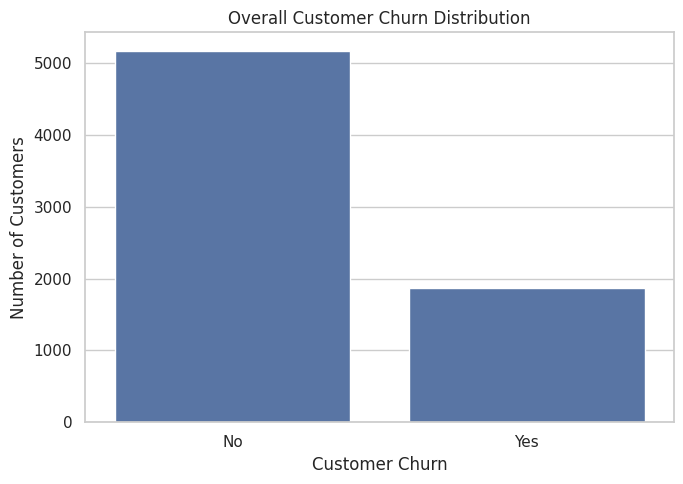

Churn counts:


,count
Churn,
No,5174
Yes,1869



Churn percentages:


,proportion
Churn,
No,73.46
Yes,26.54


In [25]:
churn_counts = df["Churn"].value_counts()

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn", order=["No", "Yes"])
plt.title("Overall Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print("Churn counts:")
display(churn_counts)

print("\nChurn percentages:")
display((df["Churn"].value_counts(normalize=True) * 100).round(2))

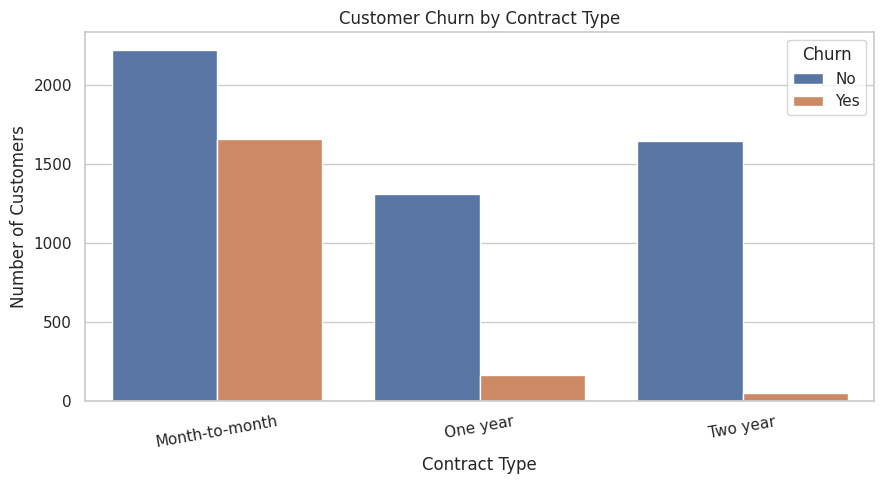

Churn percentage within each contract type:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


In [26]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="Contract", hue="Churn",
              order=["Month-to-month", "One year", "Two year"])
plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

contract_churn = pd.crosstab(
    df["Contract"], df["Churn"], normalize="index"
) * 100

print("Churn percentage within each contract type:")
display(contract_churn.round(2))

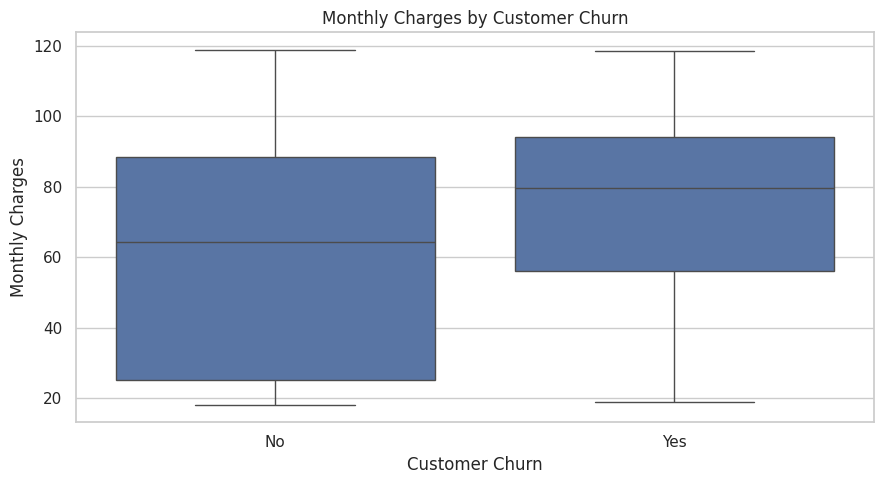

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.27,31.09,18.25,25.10,64.43,88.4,118.75
Yes,1869.0,74.44,24.67,18.85,56.15,79.65,94.2,118.35


In [27]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges",
            order=["No", "Yes"])
plt.title("Monthly Charges by Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

display(df.groupby("Churn")["MonthlyCharges"].describe().round(2))

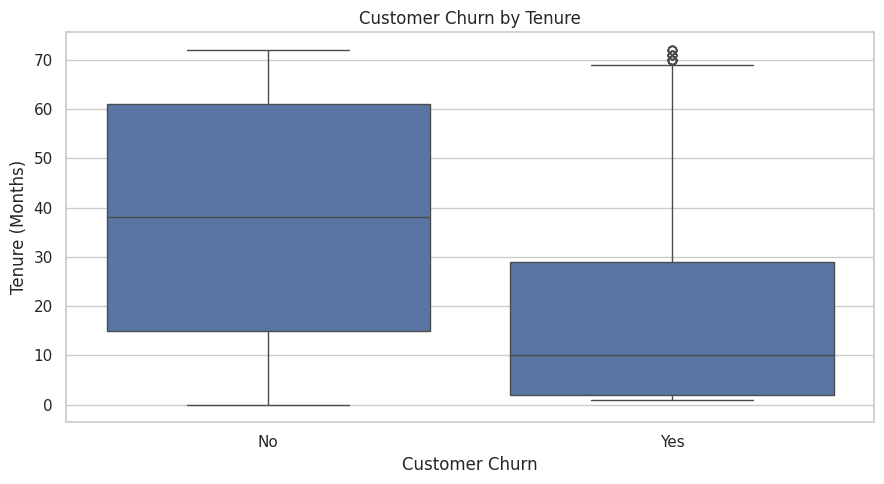

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.57,24.11,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.98,19.53,1.0,2.0,10.0,29.0,72.0


In [28]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Churn", y="tenure",
            order=["No", "Yes"])
plt.title("Customer Churn by Tenure")
plt.xlabel("Customer Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

display(df.groupby("Churn")["tenure"].describe().round(2))

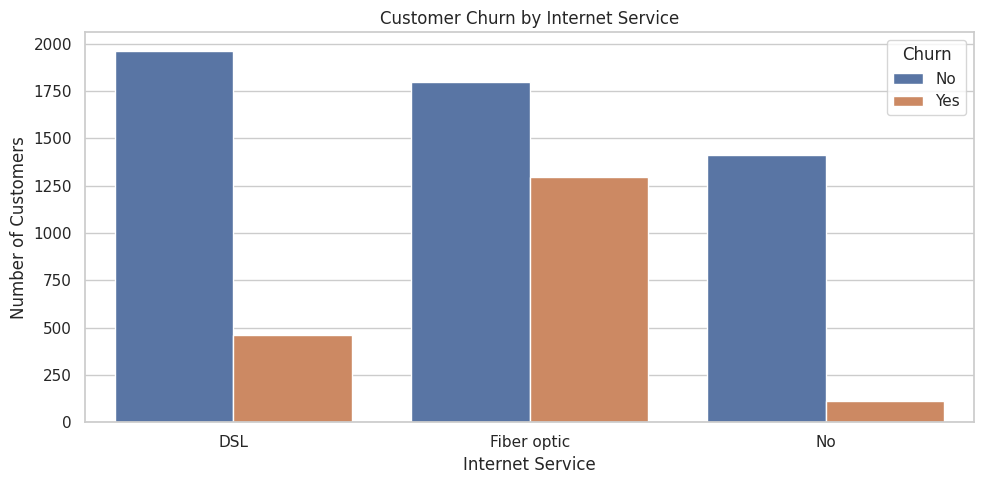

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


In [29]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="InternetService", hue="Churn")
plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

display(
    pd.crosstab(df["InternetService"], df["Churn"], normalize="index")
    .mul(100)
    .round(2)
)

In [30]:
churn_rate = (df["Churn"] == "Yes").mean() * 100

contract_rates = (
    df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int))
      .groupby("Contract")["ChurnFlag"]
      .mean() * 100
)

charge_means = df.groupby("Churn")["MonthlyCharges"].mean()
tenure_means = df.groupby("Churn")["tenure"].mean()

print(f"Overall churn rate: {churn_rate:.2f}%")

print("\nChurn rate by contract type (%):")
display(contract_rates.round(2))

print("\nAverage monthly charges by churn:")
display(charge_means.round(2))

print("\nAverage tenure by churn:")
display(tenure_means.round(2))

Overall churn rate: 26.54%

Churn rate by contract type (%):


,ChurnFlag
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83



Average monthly charges by churn:


,MonthlyCharges
Churn,
No,61.27
Yes,74.44



Average tenure by churn:


,tenure
Churn,
No,37.57
Yes,17.98


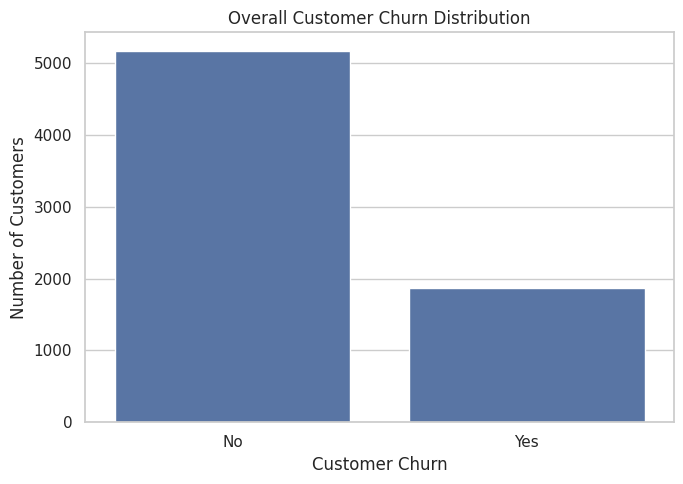

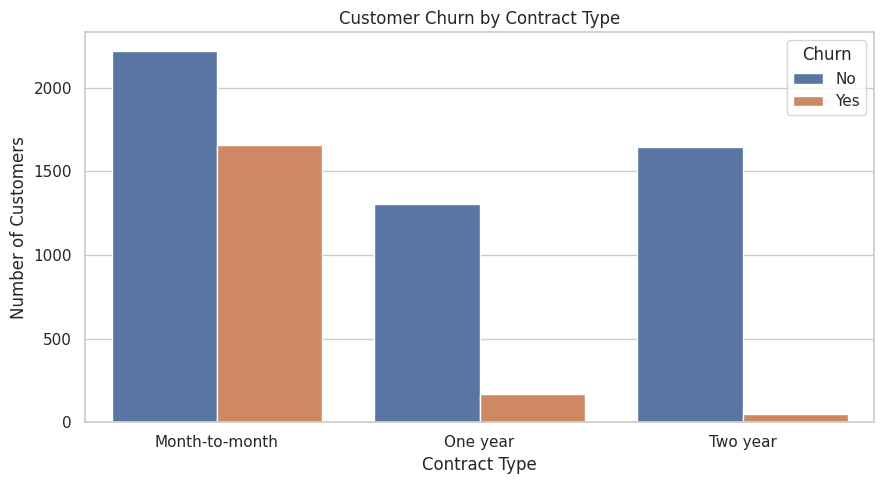

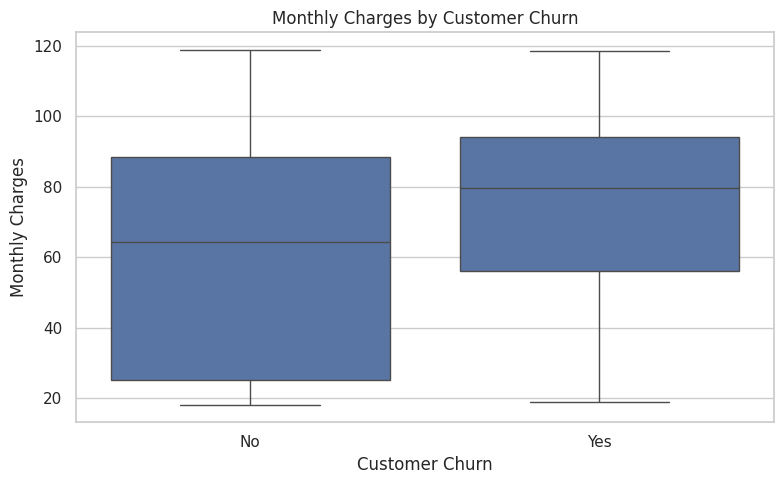

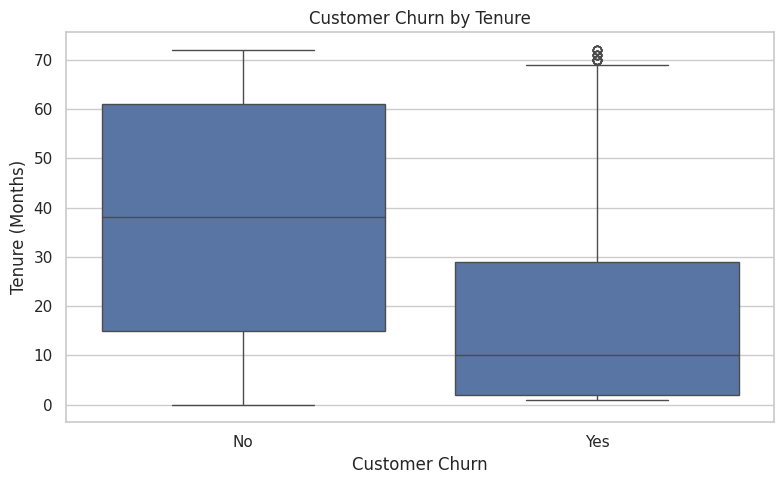

Charts saved to: /content/drive/MyDrive/AWS-Customer-Churn/outputs/figures
Saved PNG files: ['01_overall_churn.png', '02_churn_by_contract.png', '03_monthly_charges_by_churn.png', '04_tenure_by_churn.png']


In [31]:
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/AWS-Customer-Churn/outputs"
)
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Chart 1: Overall churn distribution
fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(data=df, x="Churn", order=["No", "Yes"], ax=ax)
ax.set_title("Overall Customer Churn Distribution")
ax.set_xlabel("Customer Churn")
ax.set_ylabel("Number of Customers")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "01_overall_churn.png", dpi=150)
plt.show()
plt.close(fig)

# Chart 2: Churn by contract type
fig, ax = plt.subplots(figsize=(9, 5))
sns.countplot(
    data=df, x="Contract", hue="Churn",
    order=["Month-to-month", "One year", "Two year"], ax=ax
)
ax.set_title("Customer Churn by Contract Type")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Number of Customers")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "02_churn_by_contract.png", dpi=150)
plt.show()
plt.close(fig)

# Chart 3: Monthly charges by churn
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges",
            order=["No", "Yes"], ax=ax)
ax.set_title("Monthly Charges by Customer Churn")
ax.set_xlabel("Customer Churn")
ax.set_ylabel("Monthly Charges")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "03_monthly_charges_by_churn.png", dpi=150)
plt.show()
plt.close(fig)

# Chart 4: Tenure by churn
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="tenure",
            order=["No", "Yes"], ax=ax)
ax.set_title("Customer Churn by Tenure")
ax.set_xlabel("Customer Churn")
ax.set_ylabel("Tenure (Months)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "04_tenure_by_churn.png", dpi=150)
plt.show()
plt.close(fig)

print("Charts saved to:", FIGURE_DIR)
print("Saved PNG files:", [p.name for p in FIGURE_DIR.glob("*.png")])


In [32]:
print("FINAL DATA QUALITY REPORT")
print("-" * 35)
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())
print("Customer IDs unique:", df["customerID"].is_unique)
print("Churn categories:", df["Churn"].unique())

print("\nEDA completed successfully.")

FINAL DATA QUALITY REPORT
-----------------------------------
Rows: 7043
Columns: 21
Duplicate rows: 0
Missing values: 0
Customer IDs unique: True
Churn categories: ['No' 'Yes']

EDA completed successfully.



## Main Findings from Exploratory Data Analysis (EDA)

### 1. Overall Customer Churn
The dataset contains both customers who stayed and customers who left. The number of customers who stayed is higher than the number of customers who left.

### 2. Churn by Contract Type
Customers with month-to-month contracts show higher churn than customers with one-year or two-year contracts. Longer contracts may help improve customer retention.

### 3. Churn by Monthly Charges
Customers who left generally have higher monthly charges than customers who stayed. Monthly charges may be related to customer churn.

### 4. Churn by Tenure
Customers who left generally have shorter tenure than customers who stayed. Newer customers may be more likely to leave.

### 5. Churn by Internet Service
Churn levels differ across internet service types. This suggests that the type of internet service may be associated with customer churn.

### Overall Observation
The EDA suggests that contract type, monthly charges, and customer tenure are useful factors to investigate when understanding customer churn. These patterns show relationships in the dataset and do not necessarily prove that one factor causes churn.
